# Comparison of ESM4 historical simulation NPP with observed NPP
- [x] Time-mean distribution as function of month
- [x] Variance in each month

In [1]:
import xarray as xr
import dask
from dask.diagnostics import ProgressBar
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from itertools import product

from functions import *

In [2]:
# Load observational data
basedir_obs = "/projects/SOCCOM/graemem/projects/esm4_ppe/data/processed/observations/"
localdir_obs = "NPP-RyanKeogh/NPP_MLD-EN4.2.2-0.03/"
filename_obs_climmean = "AllProducts_8D_25KM_1998_2022_climmean.nc"
ds_obs_climmean = xr.open_dataset(basedir_obs+localdir_obs+filename_obs_climmean)
filename_obs_climanomvar = "AllProducts_8D_25KM_1998_2022_climanomvar.nc"
ds_obs_climanomvar = xr.open_dataset(basedir_obs+localdir_obs+filename_obs_climanomvar)
# Load model data
yearstart,yearend = 1998,2014
variable="intpp"
basedir_esm4 = "/projects/SOCCOM/graemem/projects/esm4_ppe/data/processed/esm4historical"
yearstr = "_".join([str(yearstart),str(yearend)])
filename_prefix = ".".join(["ESM4_historical_D1",yearstr])
filename_suffix = ".".join([variable,"nc"])
filename = ".".join([filename_prefix,"climmean",filename_suffix])
outpath = "/".join([basedir_esm4,filename])
ds_esm4_climmean = xr.open_dataset(outpath)
filename = ".".join([filename_prefix,"climanomvar",filename_suffix])
outpath = "/".join([basedir_esm4,filename])
ds_esm4_climanomvar = xr.open_dataset(outpath)
# load model grid
filename_static = "ocean.static.nc"
static = xr.open_dataset("/".join([basedir_esm4,filename_static]))

# conversion
# model is mol m-2 s-1 observations are mg m-2 d-1
conversion = 86400 * 12 * 1000

/home/graemem/.conda/envs/core/lib/python3.10/site-packages/xarray/conventions.py:432: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/core/lib/python3.10/site-packages/xarray/conventions.py:432: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [3]:
# subset to save time
ds_obs_climmean = ds_obs_climmean[["VGPM"]]
ds_obs_climanomvar = ds_obs_climanomvar[["VGPM"]]

In [4]:
with ProgressBar():
    ds_obs_climmean = (ds_obs_climmean/conversion).compute()
    ds_esm4_climmean = ds_esm4_climmean.compute()
    ds_obs_climanomvar = (ds_obs_climanomvar/conversion).compute()
    ds_esm4_climanomvar = ds_esm4_climanomvar.compute()
    static = static.compute()

In [5]:
# Some useful properties
npr = len(ds_obs_climmean.data_vars)
npr

1

## Climatological mean

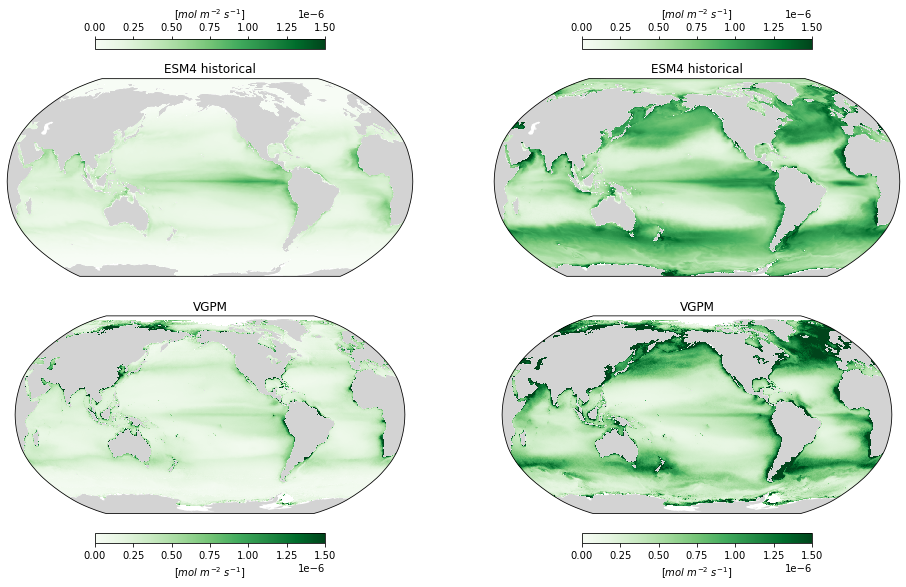

In [10]:
subplot_kw = {'projection':ccrs.Robinson(central_longitude=-150)}
kw_args_min = {'vmin':0,'vmax':1.5e-6,'cmap':'Greens'}
kw_args_max = {'vmin':0,'vmax':1.5e-6,'cmap':'Greens'}
fig,axarr = plt.subplots(figsize=(16,4*(npr+1)),nrows=(npr+1),ncols=2,subplot_kw = subplot_kw)

# Plot model
damin = ds_esm4_climmean.min('month')["intpp"]
damax = ds_esm4_climmean.max('month')["intpp"]
# Minimum
axnow = axarr[0,0]
immin,axnow = draw_globalplot_esm4(axnow,damin,static,**kw_args_min)
axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
axnow.set_title("ESM4 historical")
# Maximum
axnow = axarr[0,1]
immax,axnow = draw_globalplot_esm4(axnow,damax,static,**kw_args_max)
axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
axnow.set_title("ESM4 historical")

# Plot observations
dsmin = ds_obs_climmean.min('month')
dsmax = ds_obs_climmean.max('month')
for i,(damin,damax) in enumerate(zip(dsmin.values(),dsmax.values())):
    # Minimum
    axnow = axarr[i+1,0]
    immin,axnow = draw_globalplot(axnow,damin,**kw_args_min)
    axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
    axnow.set_title(damin.name)
    # Maximum
    axnow = axarr[i+1,1]
    immax,axnow = draw_globalplot(axnow,damax,**kw_args_max)
    axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
    axnow.set_title(damax.name)

# Colorbars
width = 0.2
bboxmin = axarr[0,0].get_position()
bboxmax = axarr[0,1].get_position()
# Centre on axis location
centremin = bboxmin.bounds[0]+bboxmin.bounds[2]/2
centremax = bboxmax.bounds[0]+bboxmax.bounds[2]/2
leftmin = centremin-width/2
leftmax = centremax-width/2
height = 5e-2*bboxmin.bounds[3] # 5% of subplot axis height
# top colorbars
bottomtop = bboxmin.bounds[1]+bboxmin.bounds[3]+3*height
# bottom colorbars
bboxmin = axarr[npr-1+1,0].get_position()
bottombottom = bboxmin.bounds[1]-3*height

lefts = [leftmin,leftmax]
bottoms = [bottomtop, bottombottom]

for left,bottom in product(lefts,bottoms):
    if left==leftmin:
        im=immin
    else:
        im=immax
    if bottom==bottomtop:
        tick_position='top'
    else:
        tick_position='bottom'
    position = [left,bottom,width,height]
    axcb,imcb = add_colorbar(fig,im,position,tick_position)
    imcb.set_label('[$mol\ m^{-2}\ s^{-1}$]')
    imcb.ax.xaxis.set_label_position(tick_position)
    
save_fig(fig,'fig.model-obs-comparison_npp.climmean')

## Climatological variance of anomalies

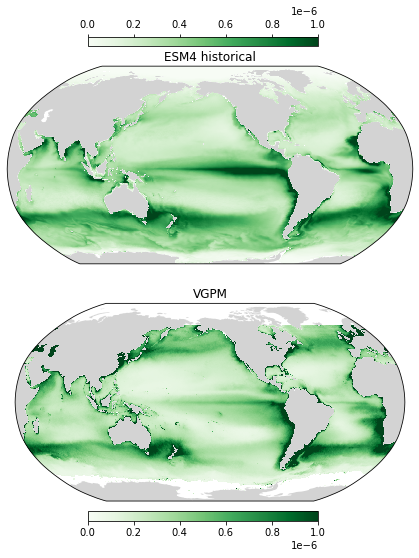

In [13]:
month = 10

dsmonth = ds_obs_climanomvar.sel(month=month)
subplot_kw = {'projection':ccrs.Robinson(central_longitude=-150)}
kw_args = {'vmin':0,'vmax':1e-6,'cmap':'Greens'}
fig,axarr = plt.subplots(figsize=(8,4*(npr+1)),nrows=npr+1,subplot_kw = subplot_kw)

da = ds_esm4_climanomvar["intpp"].sel(month=month)
axnow = axarr[0]
im,axnow = draw_globalplot_esm4(axnow,da,static,**kw_args)
axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
axnow.set_title("ESM4 historical")

for i,da in enumerate(dsmonth.values()):
    axnow = axarr[i+1]
    im,axnow = draw_globalplot(axnow,da,**kw_args)
    axnow.add_feature(cfeature.LAND,facecolor='lightgrey')
    axnow.set_title(da.name)

# colorbar
width = 0.4
left = 0.5-width/2
bbox = axarr[0].get_position()
height = 5e-2*bbox.bounds[3]
bottomtop = bbox.bounds[1]+bbox.bounds[3]+2*height
bbox = axarr[-1].get_position()
bottombottom = bbox.bounds[1]-2*height

bottoms = [bottomtop,bottombottom]

for bottom in bottoms:
    if bottom==bottomtop:
        tick_position='top'
    else:
        tick_position='bottom'
    position = [left,bottom,width,height]
    add_colorbar(fig,im,position,tick_position)
    
save_fig(fig,'fig.model-obs-comparison_npp.climanomvar.month-'+str(month).zfill(2))